The system equations are:
$$\frac{ds}{dt} = \alpha c - s(1-c)$$
$$\frac{dc}{dt} = \beta(\alpha c - s(1-c)) - \epsilon c$$
with parameters $\alpha = 0.6$, $\beta = 1.25$, and $\epsilon = 0.4$.

In [1]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="MM_Kinetics")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "alpha": 0.6,
    "beta": 1.25,
    "epsilon": 0.4,
}

# Define the ODEs.
varspecs = {
    's': "alpha*c-s*(1-c)",
    'c': "-beta*(alpha*c-s*(1-c))-epsilon*c",
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "s": 1.0,
    "c": 0.0,
}

# Define a domain for the variables, it is used when finding steady states, plotting null clines and vector fields.
domain = {
    'c': [-0.1, 1.0],
    's': [-0.1, 1.0]}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...
Plotting trajectory part A...


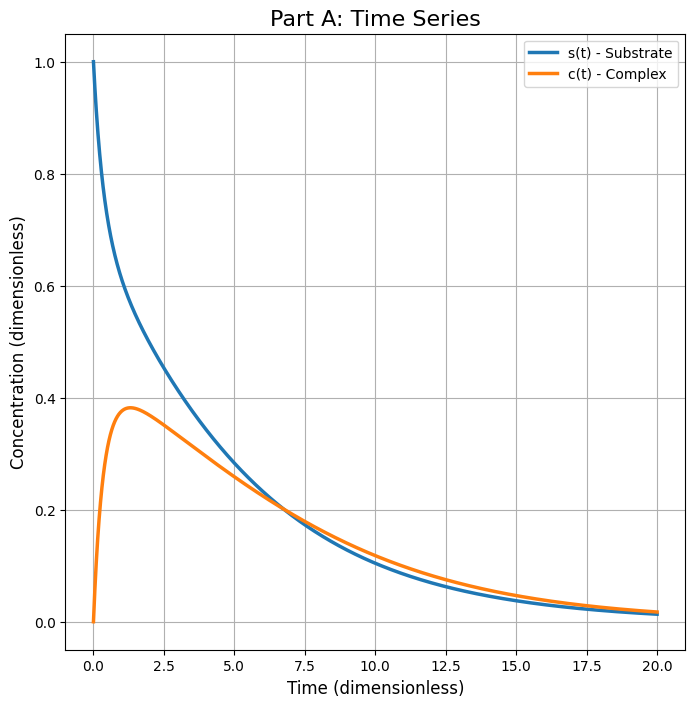

Plotting phase trajectory part A...


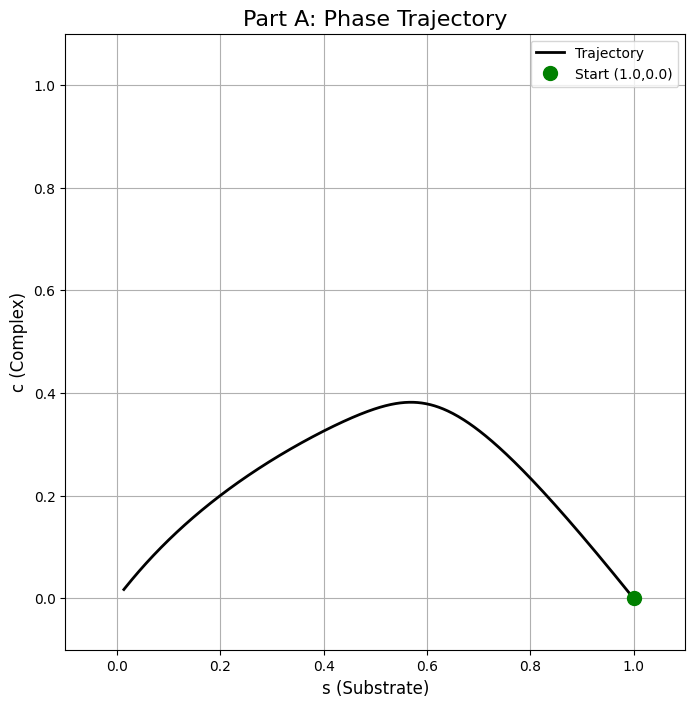

Plotting phase trajectory part B...


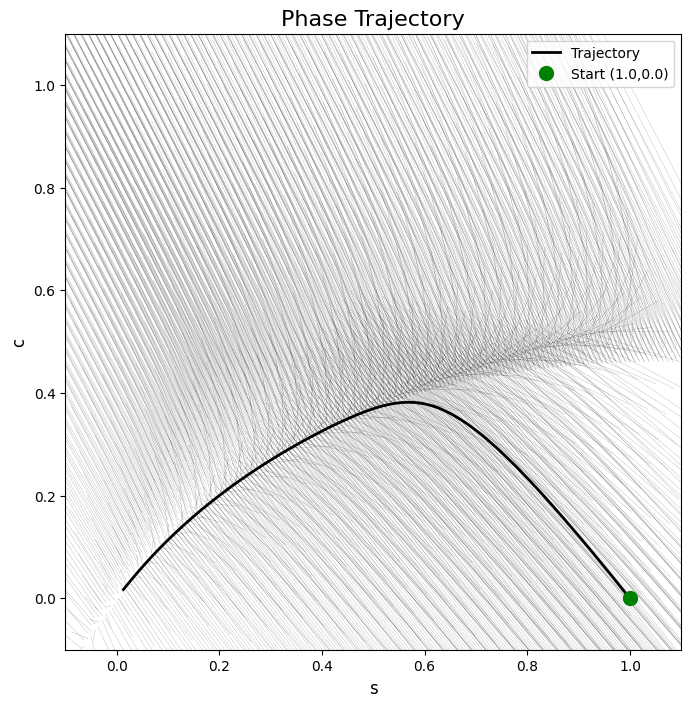

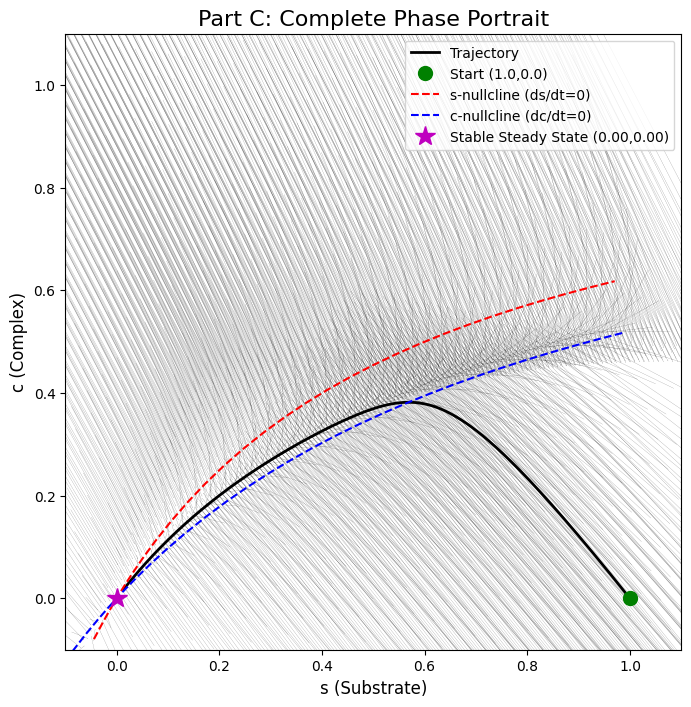

In [3]:
# This module is used to plot phaseplanes and nullclines
from PyDSTool.Toolbox import phaseplane as pp

# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 20])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
fig_A1, ax_A1 = plt.subplots(figsize=(8, 8))
ax_A1.plot(points['t'], points['s'], label='s(t) - Substrate', lw=2.5)
ax_A1.plot(points['t'], points['c'], label='c(t) - Complex', lw=2.5)
ax_A1.set_title('Part A: Time Series', fontsize=16)
ax_A1.set_xlabel('Time (dimensionless)', fontsize=12)
ax_A1.set_ylabel('Concentration (dimensionless)', fontsize=12)
plt.legend()
ax_A1.grid(True)
plt.show()

# 4. Plot the phase trajectory
print("Plotting phase trajectory part A...")
fig_A2, ax_A2 = plt.subplots(figsize=(8, 8))
ax_A2.plot(points['s'], points['c'], 'k-', lw=2, label='Trajectory')
ax_A2.plot(ics['s'], ics['c'], 'go', ms=10, label=f'Start ({ics["s"]},{ics["c"]})')
ax_A2.set_title('Part A: Phase Trajectory', fontsize=16)
ax_A2.set_xlabel('s (Substrate)', fontsize=12)
ax_A2.set_ylabel('c (Complex)', fontsize=12)
ax_A2.set_xlim(-0.1, 1.1)
ax_A2.set_ylim(-0.1, 1.1) 
plt.legend()
ax_A2.grid(True)
plt.show()

# 5. Plotting Part B: Adding the Vector Field
print("Plotting phase trajectory part B...")
fig_B, ax_B = plt.subplots(figsize=(8, 8))
ax_B.plot(points['s'], points['c'], 'k-', lw=2, label='Trajectory')
ax_B.plot(ics['s'], ics['c'], 'go', ms=10, label=f'Start ({ics["s"]},{ics["c"]})')

# Plot vector field, uses a scale exponent. Not a fan of the scale exponent, there is no option to normalise.
pp.plot_PP_vf(ode_sys, "s", "c", N=40, scale_exp=0)

ax_B.set_title('Part B: Phase Portrait with Vector Field', fontsize=16)
ax_B.set_xlabel('s (Substrate)', fontsize=12)
ax_B.set_ylabel('c (Complex)', fontsize=12)
ax_B.set_title('Phase Trajectory', fontsize=16)
ax_B.set_xlabel('s', fontsize=12)
ax_B.set_ylabel('c', fontsize=12)
ax_B.set_xlim(-0.1, 1.1)
ax_B.set_ylim(-0.1, 1.1) 
ax_B.legend()
ax_B.set_aspect('equal', adjustable='box')
plt.show()

# 6 Plotting Part C: The Complete Phase Portrait

# First find the SS (fixed points). It returns a list as there can be multiple fixed points.

fp_coord = pp.find_fixedpoints(ode_sys, n=4, eps=1e-8)[0]

# Now find the nullcline, giving the fixed points will help with convergence.
nulls_s, nulls_c = pp.find_nullclines(ode_sys, 's', 'c', n=3, eps=1e-8, max_step=0.05, fps = [fp_coord])

fig_C, ax_C = plt.subplots(figsize=(8, 8))

ax_C.plot(points['s'], points['c'], 'k-', lw=2, label='Trajectory')
ax_C.plot(ics['s'], ics['c'], 'go', ms=10, label=f'Start ({ics["s"]},{ics["c"]})')
ax_C.set_title('Part C: Complete Phase Portrait', fontsize=16)
ax_C.set_xlabel('s (Substrate)', fontsize=12)
ax_C.set_ylabel('c (Complex)', fontsize=12)

# Plot vector field, uses a scale exponent. Not a fan of the scale exponent, there is no option to normalise. Preferably be done manually.
pp.plot_PP_vf(ode_sys, "s", "c", N=40, scale_exp=0)



# Plot the nullclines
plt.plot(nulls_s[:,0], nulls_s[:,1], 'r--', label='s-nullcline (ds/dt=0)')
plt.plot(nulls_c[:,0], nulls_c[:,1], 'b--', label='c-nullcline (dc/dt=0)')

# Plot the fixed point
ax_C.plot(fp_coord["s"], fp_coord["c"], 'm*', ms=15, label=f'Stable Steady State ({fp_coord["s"]:.2f},{fp_coord["c"]:.2f})')

ax_C.set_xlim(-0.1, 1.1)
ax_C.set_ylim(-0.1, 1.1) 
ax_C.legend()
ax_C.set_aspect('equal', adjustable='box')
plt.show()